# Phần Thành viên 3: chạy từng bước trên Jupyter (Anaconda)

Chạy từng ô theo thứ tự (chọn ô, bấm **Shift + Enter**). Ô nào có chữ **SỬA** thì chỉnh đường dẫn cho đúng máy bạn trước khi chạy.

**Trước khi bắt đầu:** giải nén `tv3_package.zip`, đặt file notebook này **vào trong thư mục `tv3_package`** (cùng chỗ với `eval.py`, `measure.py`).

## Bước 1. Kiểm tra môi trường

In [1]:
import sys, os, platform
os.environ["PYTHONUTF8"] = "1"   # Windows: in được tiếng Việt khi chạy script bằng !
os.environ["PYTHONIOENCODING"] = "utf-8"
print("Python:", sys.version.split()[0], "|", platform.system())
print("Thư mục hiện tại:", os.getcwd())
print("Có eval.py ở đây không:", os.path.exists("eval.py"))
for m in ["numpy", "cv2", "skimage", "pandas", "torch", "lpips", "pyiqa"]:
    try:
        __import__(m); print(f"  {m:8s} OK")
    except Exception:
        print(f"  {m:8s} CHƯA CÀI")
try:
    import torch
    print("GPU (CUDA):", torch.cuda.is_available())
except Exception:
    pass

Python: 3.14.6 | Windows
Thư mục hiện tại: C:\Users\asus\Downloads\XLA\tv3_package\tv3_package
Có eval.py ở đây không: True
  numpy    OK
  cv2      OK
  skimage  OK
  pandas   OK
  torch    OK
  lpips    OK
  pyiqa    OK
GPU (CUDA): False


Nếu dòng "Có eval.py ở đây không" là `False`: chạy ô tiếp theo để trỏ đúng thư mục, **hoặc** đóng notebook rồi mở lại từ trong thư mục `tv3_package`.

In [ ]:
# SỬA: đường dẫn tới thư mục tv3_package (Windows dùng dấu / hoặc r"...")
THU_MUC = r"D:/tv3_package"
os.chdir(THU_MUC)
print("Đang ở:", os.getcwd())
print(sorted(os.listdir(".")))

## Bước 2. Cài thư viện (chỉ cần làm một lần)

`%pip` cài vào đúng môi trường của notebook. Các gói đầu nhẹ, gói cuối (`torch`, `lpips`, `pyiqa`) nặng, có thể mất vài phút.
Nếu `torch/lpips/pyiqa` lỗi thì **vẫn chạy tiếp được**: PSNR và SSIM vẫn ra, LPIPS/NIQE/BRISQUE sẽ để trống.

In [ ]:
%pip install numpy opencv-python scikit-image pandas matplotlib

In [ ]:
%pip install torch lpips pyiqa

Sau khi cài xong gói nặng, **khởi động lại kernel** (menu Kernel → Restart), chạy lại Bước 1 để kiểm tra, rồi quay lại đây.

## Bước 3. Đặt ảnh test vào `test_cases/`

Cấu trúc (tên file ở `input` và `gt` phải **trùng nhau**):
```
test_cases/LOLv1/input   15 ảnh      test_cases/LOLv1/gt        15 ảnh
test_cases/LOLv2_Real/input 100 ảnh  test_cases/LOLv2_Real/gt   100 ảnh
test_cases/DICM/input    69 ảnh      test_cases/LIME/input      10 ảnh
```
Bộ LOL, DICM, LIME tải theo hướng dẫn trong README của repo HVI-CIDNet (xem Bước 6). Ảnh test của LOL nằm ở thư mục `eval15` (v1) hoặc `Real_captured/Test` (v2-Real) tùy bản tải; chép ảnh tối vào `input`, ảnh sáng vào `gt`.
Chạy ô dưới để biết còn thiếu gì:

In [ ]:
!"{sys.executable}" prepare_test_cases.py check

## Bước 4. Xử lý 20 ảnh tự chụp

1. Tạo thư mục `anh_goc` trong `tv3_package`, chép 20 ảnh điện thoại vào.
2. Đổi tên theo nhóm: `red_01.jpg` ... `red_06.jpg`, `night_01.jpg` ... `night_06.jpg`, `backlit_01.jpg` ... `backlit_04.jpg`, `dark_01.jpg` ... `dark_04.jpg`.
   (đuôi `.jpg`/`.png`/`.jpeg` đều được; ảnh HEIC của iPhone cần đổi sang JPG trước)

In [10]:
!"{sys.executable}" prepare_test_cases.py custom --raw anh_goc

Da xu ly 20 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\test_cases\custom_night\input
Theo nhom: {'red': 6, 'night': 6, 'backlit': 4, 'dark': 4}
Manifest: C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\test_cases\custom_night\manifest.csv
Goi y phan bo 20 anh: red 6, night 6, backlit 4, dark 4. Dien cot camera_phone (ten dien thoai).


Sau khi chạy: mở `test_cases/custom_night/manifest.csv`, điền cột `camera_phone` (tên điện thoại).

## Bước 5. Thống kê lược đồ xám (số thay cho "85%" trong báo cáo)

In [ ]:
!"{sys.executable}" prepare_test_cases.py hist
import pandas as pd
pd.read_csv("histogram_stats.csv")

## Bước 6. Lấy mã chính thức của HVI-CIDNet

Cần cài **git** (nếu báo "git không nhận ra": mở Anaconda Prompt chạy `conda install git`, hoặc vào trang GitHub bấm Code → Download ZIP rồi giải nén vào `tv3_package/HVI-CIDNet`).
Dùng link **https** (link `git@github.com:...` trong README cần khóa SSH).

In [2]:
!git clone https://github.com/Fediory/HVI-CIDNet

fatal: destination path 'HVI-CIDNet' already exists and is not an empty directory.


**Lưu ý trùng tên:** repo cũng có `eval.py` và `measure.py`. Notebook luôn chạy file của repo với thư mục làm việc là `HVI-CIDNet` (qua hàm `chay_repo` ở Bước 7); file của bạn chạy ở thư mục chứa notebook này. Đừng chép lẫn hai bộ file.

README ghi Python 3.7 + PyTorch 1.13.1, nhưng **đừng chạy `pip install -r requirements.txt`**: file đó ghim phiên bản cũ (torch 1.13.1, scipy 1.7.3, Pillow 9.5...) và sẽ phá `torch` bạn đã cài. Mã đánh giá (`eval.py`) chỉ cần vài thư viện, cài riêng ô dưới (nếu báo thiếu thêm thư viện nào thì `%pip install` thư viện đó).

In [3]:
%pip install einops huggingface_hub safetensors scipy tqdm torchvision pillow

Note: you may need to restart the kernel to use updated packages.


### Tải trọng số và dữ liệu (làm tay, không tự động hóa được)

Link nằm trong README của repo; Baidu Pan cần tài khoản Trung Quốc, nên dùng **One Drive** (mã `yixu`).
- Trọng số: đặt vào `HVI-CIDNet/weights/` đúng cấu trúc README. Cần ít nhất `LOLv1/wo_perc.pth`, `LOLv2_real/best_SSIM.pth`, `LOLv2_syn/w_perc.pth`.
- Dữ liệu: **không cần** đặt vào `HVI-CIDNet/datasets/`. Bước 7 chạy mô hình thẳng trên `test_cases/<BỘ>/input` mà Bước 3 đã chuẩn bị.

Chạy ô dưới để kiểm tra đã có đủ file trọng số chưa:

In [2]:
CAN = ["LOLv1/wo_perc.pth", "LOLv2_real/best_SSIM.pth", "LOLv2_syn/w_perc.pth"]
for w in CAN:
    p = os.path.join("HVI-CIDNet", "weights", w)
    print("OK   " if os.path.exists(p) else "THIẾU", p)

OK    HVI-CIDNet\weights\LOLv1/wo_perc.pth
OK    HVI-CIDNet\weights\LOLv2_real/best_SSIM.pth
OK    HVI-CIDNet\weights\LOLv2_syn/w_perc.pth


## Bước 7. Chạy HVI-CIDNet và chép ảnh ra

Đã đọc mã `eval.py` của repo. Hai điều quan trọng:
- **`eval.py` của repo bắt buộc có GPU** (báo `No GPU found` nếu không có). Máy bạn chạy CPU nên hàm dưới tự tạo `HVI-CIDNet/eval_cpu.py` (đổi `.cuda()` thành `.cpu()`); không sửa file gốc.
- Dùng đúng chế độ chính thức của repo cho từng bộ, vì mỗi chế độ bật cơ chế riêng (LOLv1 dùng `--lol`, LOLv2-Real dùng `--lol_v2_real --best_SSIM` với alpha 0,82 cài sẵn, DICM/LIME dùng `--unpaired`). Hàm `chay_bo` chép ảnh từ `test_cases/<BỘ>/input` sang `HVI-CIDNet/datasets/...` đúng chỗ repo cần, chạy, rồi chép ảnh ra `results/<BỘ>/HVI-CIDNet/`.

| Bộ | Lệnh repo | Trọng số |
|---|---|---|
| LOLv1 | `--lol` | `LOLv1/wo_perc.pth` |
| LOLv2_Real | `--lol_v2_real --best_SSIM` | `LOLv2_real/best_SSIM.pth` |
| DICM, LIME, custom_night | `--unpaired ...` (alpha 1,0, gamma 1,0) | `LOLv2_syn/w_perc.pth` |

**Ghi lại trọng số bạn đã dùng** để đưa vào báo cáo. Chạy CPU: ô có thể im lặng vài phút (LOLv2_Real 100 ảnh lâu nhất), dấu `[*]` bên trái là còn đang chạy.

In [3]:
import shutil, glob, subprocess
IMG = (".png", ".jpg", ".jpeg", ".bmp")
REPO = "HVI-CIDNet"
W_UNPAIRED = "./weights/LOLv2_syn/w_perc.pth"

# bộ test -> (thư mục dữ liệu repo cần, lệnh repo, trọng số, thư mục ảnh ra của repo)
BO = {
    "LOLv1":      ("LOLdataset/eval15/low",        ["--lol"],                          "./weights/LOLv1/wo_perc.pth",       "LOLv1"),
    "LOLv2_Real": ("LOLv2/Real_captured/Test/Low", ["--lol_v2_real", "--best_SSIM"],   "./weights/LOLv2_real/best_SSIM.pth", "LOLv2_real"),
    "DICM":       ("DICM", ["--unpaired", "--DICM", "--unpaired_weights", W_UNPAIRED, "--alpha", "1.0", "--gamma", "1.0"], W_UNPAIRED, "DICM"),
    "LIME":       ("LIME", ["--unpaired", "--LIME", "--unpaired_weights", W_UNPAIRED, "--alpha", "1.0", "--gamma", "1.0"], W_UNPAIRED, "LIME"),
}

def chon_script():
    """Có GPU thì dùng eval.py của repo; không có thì tạo eval_cpu.py (.cuda() -> .cpu())."""
    import torch
    if torch.cuda.is_available():
        return "eval.py"
    s = open(os.path.join(REPO, "eval.py"), encoding="utf-8").read()
    s = s.replace(".cuda()", ".cpu()").replace("cuda = True", "cuda = False")
    open(os.path.join(REPO, "eval_cpu.py"), "w", encoding="utf-8").write(s)
    return "eval_cpu.py"

def chay_repo(args):
    """Chạy eval của repo (thư mục làm việc = HVI-CIDNet), in phần cuối log. Trả True nếu thành công."""
    env = dict(os.environ, PYTHONUTF8="1", PYTHONIOENCODING="utf-8")
    r = subprocess.run([sys.executable, chon_script()] + args, cwd=REPO, env=env,
                       capture_output=True, text=True, encoding="utf-8", errors="replace")
    print(((r.stdout or "") + (r.stderr or ""))[-3000:])
    if r.returncode != 0:
        print("!! Lệnh của repo báo lỗi (xem log ngay phía trên). Dán lỗi này cho Claude.")
    return r.returncode == 0

def chep_ket_qua(thu_muc_ra, dich):
    os.makedirs(dich, exist_ok=True)
    n = 0
    for f in glob.glob(os.path.join(thu_muc_ra, "*")):
        if f.lower().endswith(IMG):
            shutil.copy(f, dich); n += 1
    return n

def kiem_tra_ten(bo, dich):
    inp = {os.path.splitext(f)[0] for f in os.listdir(os.path.join("test_cases", bo, "input"))}
    out = {os.path.splitext(f)[0] for f in os.listdir(dich)}
    if inp - out:
        print("  !! Thiếu ảnh ra cho:", sorted(inp - out)[:5], "... (tên file ảnh ra phải trùng ảnh input)")

def chay_bo(bo):
    cop, args, w, ra = BO[bo]
    if not os.path.exists(os.path.join(REPO, w)):
        print(f"!! Chưa có trọng số {REPO}/{w}. Đặt file vào đúng chỗ rồi chạy lại."); return
    dich_dl = os.path.join(REPO, "datasets", *cop.split("/"))
    shutil.copytree(os.path.join("test_cases", bo, "input"), dich_dl, dirs_exist_ok=True)
    ra_dir = os.path.join(REPO, "output", ra)
    shutil.rmtree(ra_dir, ignore_errors=True)          # xóa kết quả cũ để không lẫn
    if chay_repo(args):
        dich = os.path.join("results", bo, "HVI-CIDNet")
        n = chep_ket_qua(ra_dir, dich)
        print(f"{bo}: chép {n} ảnh -> {dich}")
        kiem_tra_ten(bo, dich)

def chay_custome(thu_muc_input, dich, w=W_UNPAIRED, alpha="1.0", gamma="1.0"):
    """Chạy trên một thư mục ảnh bất kỳ (ảnh tự chụp, ảnh ca thất bại). Ảnh ra: HVI-CIDNet/output/custome."""
    if not os.path.exists(os.path.join(REPO, w)):
        print(f"!! Chưa có trọng số {REPO}/{w}."); return
    ra_dir = os.path.join(REPO, "output", "custome")
    shutil.rmtree(ra_dir, ignore_errors=True)
    ok = chay_repo(["--unpaired", "--custome", "--custome_path", os.path.abspath(thu_muc_input),
                    "--unpaired_weights", w, "--alpha", alpha, "--gamma", gamma])
    if ok:
        print(f"{dich}: chép {chep_ket_qua(ra_dir, dich)} ảnh")

In [11]:
# Chạy thử LOLv1 trước. Ra đủ 15 ảnh thì bỏ dấu # ở các bộ còn lại.
#chay_bo("LOLv1")
# chay_bo("LOLv2_Real")
# chay_bo("DICM")
# chay_bo("LIME")
# Ảnh tự chụp (sau khi đã chạy Bước 4):
chay_custome("test_cases/custom_night/input", "results/custom_night/HVI-CIDNet")

Pre-trained model is loaded.
Evaluation:
===> End evaluation

100%|██████████| 20/20 [00:40<00:00,  2.03s/it]

results/custom_night/HVI-CIDNet: chép 20 ảnh


Nếu báo lỗi **thiếu thư viện** (`No module named ...`): `%pip install tên_thư_viện`, rồi chạy lại ô. Lỗi khác: dán nguyên log lên cho Claude. Ảnh CLAHE/Gamma tự code của TV1 được tạo ở Bước 8, bạn không cần chép tay.

## Bước 8. Tạo ảnh đối chứng: OpenCV và bản tự code của TV1

Hai bản dùng cùng tham số (CLAHE clip 2.0, lưới 8×8, Gamma 0.4) để so sánh công bằng. Cần đã cài `matplotlib` (file của TV1 có import nó).

In [7]:
!"{sys.executable}" eval.py baselines
!"{sys.executable}" eval.py scratch

LOLv1/opencv_clahe: 15 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\results\LOLv1\opencv_clahe
LOLv1/opencv_gamma: 15 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\results\LOLv1\opencv_gamma
LOLv2_Real/opencv_clahe: 100 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\results\LOLv2_Real\opencv_clahe
LOLv2_Real/opencv_gamma: 100 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\results\LOLv2_Real\opencv_gamma
DICM/opencv_clahe: 69 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\results\DICM\opencv_clahe
DICM/opencv_gamma: 69 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\results\DICM\opencv_gamma
LIME/opencv_clahe: 10 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\results\LIME\opencv_clahe
LIME/opencv_gamma: 10 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\results\LIME\opencv_gamma
custom_night/opencv_clahe: 0 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\results\custom_night\openc

## Bước 9. Đo chỉ số và ghi CSV

In [12]:
!"{sys.executable}" eval.py baselines --datasets custom_night
!"{sys.executable}" eval.py scratch --datasets custom_night
!"{sys.executable}" eval.py evaluate --datasets custom_night --out-csv quantitative_results_custom.csv --per-image-csv per_image_custom.csv

custom_night/opencv_clahe: 20 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\results\custom_night\opencv_clahe
custom_night/opencv_gamma: 20 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\results\custom_night\opencv_gamma
custom_night/scratch_clahe: 20 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\results\custom_night\scratch_clahe
custom_night/scratch_gamma: 20 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\results\custom_night\scratch_gamma
custom_night   HVI-CIDNet       n= 20 PSNR=- SSIM=- LPIPS=- NIQE=3.9179
custom_night   opencv_clahe     n= 20 PSNR=- SSIM=- LPIPS=- NIQE=3.8685
custom_night   opencv_gamma     n= 20 PSNR=- SSIM=- LPIPS=- NIQE=4.1743
custom_night   scratch_clahe    n= 20 PSNR=- SSIM=- LPIPS=- NIQE=3.8855
custom_night   scratch_gamma    n= 20 PSNR=- SSIM=- LPIPS=- NIQE=4.1715

Da ghi quantitative_results_custom.csv (34 dong bai bao + 5 dong nhom tu chay)
Da ghi per_image_custom.csv


C:\Users\asus\anaconda3\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\asus\anaconda3\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [8]:
!"{sys.executable}" eval.py evaluate

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to C:\Users\asus/.cache\torch\hub\checkpoints\alexnet-owt-7be5be79.pth
Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/niqe_modelparameters.mat" to C:\Users\asus\.cache\torch\hub\pyiqa\niqe_modelparameters.mat

Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/brisque_svm_weights.pth" to C:\Users\asus\.cache\torch\hub\pyiqa\brisque_svm_weights.pth

LOLv1          HVI-CIDNet       n= 15 PSNR=28.1935 SSIM=0.8884 LPIPS=0.0985 NIQE=4.6678
LOLv1          opencv_clahe     n= 15 PSNR=17.6710 SSIM=0.4441 LPIPS=0.4174 NIQE=8.5054
LOLv1          opencv_gamma     n= 15 PSNR=22.2964 SSIM=0.6325 LPIPS=0.3444 NIQE=7.6456
LOLv1          scratch_clahe    n= 15 PSNR=17.4334 SSIM=0.4436 LPIPS=0.4221 NIQE=8.6703
LOLv1          scratch_gamma    n= 15 PSNR=22.2428 SSIM=0.6344 LPIPS=0.3454 NIQE=7.5624
LOLv2_Real     HVI-CIDNet       n=100 PSNR=23.8977 SSIM=0.8705 LPIPS=0.

C:\Users\asus\anaconda3\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\asus\anaconda3\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)

  0%|          | 0.00/233M [00:00<?, ?B/s]
  0%|          | 640k/233M [00:00<00:48, 4.99MB/s]
  1%|          | 2.75M/233M [00:00<00:17, 13.4MB/s]
  2%|?         | 5.00M/233M [00:00<00:13, 17.3MB/s]
  3%|?         | 7.38M/233M [00:00<00:11, 19.9MB/s]
  4%|?         | 9.75M/233M [00:00<00:10, 21.3MB/s]
  5%|?         | 12.1M/233M [00:00<00:10, 22.2MB/s]
  6%|?         | 14.

In [9]:
import pandas as pd
df = pd.read_csv("quantitative_results.csv")
df[df["source"] == "nhom_tu_chay"].dropna(subset=["psnr", "niqe"], how="all")

,dataset,method,n_images,psnr,ssim,lpips,niqe,brisque,gt_mean,source,note
34,LOLv1,HVI-CIDNet,15,28.1935,0.8884,0.0985,4.6678,27.7135,yes,nhom_tu_chay,NaN
35,LOLv1,opencv_clahe,15,17.6710,0.4441,0.4174,8.5054,39.9868,yes,nhom_tu_chay,NaN
36,LOLv1,opencv_gamma,15,22.2964,0.6325,0.3444,7.6456,24.4566,yes,nhom_tu_chay,NaN
37,LOLv1,scratch_clahe,15,17.4334,0.4436,0.4221,8.6703,41.2769,yes,nhom_tu_chay,NaN
38,LOLv1,scratch_gamma,15,22.2428,0.6344,0.3454,7.5624,24.2290,yes,nhom_tu_chay,NaN
39,LOLv2_Real,HVI-CIDNet,100,23.8977,0.8705,0.1185,4.5446,17.3740,no,nhom_tu_chay,NaN
40,LOLv2_Real,opencv_clahe,100,11.8247,0.4099,0.3630,7.5951,24.6956,no,nhom_tu_chay,NaN
41,LOLv2_Real,opencv_gamma,100,18.6998,0.6567,0.3178,7.3875,27.0480,no,nhom_tu_chay,NaN
42,LOLv2_Real,scratch_clahe,100,11.7690,0.4036,0.3645,7.5940,24.7434,no,nhom_tu_chay,NaN
43,LOLv2_Real,scratch_gamma,100,18.7568,0.6576,0.3192,7.3667,26.9319,no,nhom_tu_chay,NaN


Kết quả: `quantitative_results.csv` (gồm dòng bài báo và dòng nhóm tự chạy, cột `source` phân biệt) và `per_image_results.csv` (từng ảnh).
So số của bạn với dòng `bai_bao_Bang1`: lệch nhẹ là bình thường (khác cách cài SSIM/LPIPS), lệch lớn thì kiểm tra lại ảnh đầu ra và việc ghép tên file.

## Bước 10. Bốn ca thất bại

1. Chọn ảnh cho từng ca, chép vào `test_cases/failure_cases/<ca>/input/` (`case1_color_shift`, `case2_k_alpha`, `case3_total_dark`, `case4_backlit`).
2. Chạy mô hình bằng `chay_custome("test_cases/failure_cases/<ca>/input", "results/failure_cases/<ca>/HVI-CIDNet")` (hàm ở Bước 7) + OpenCV (`eval.py baselines --datasets failure_cases/<ca>`), đặt kết quả ở `results/failure_cases/<ca>/<tên phương pháp>/` (tên file trùng ảnh input; tên phương pháp: `HVI-CIDNet`, `opencv_clahe`...).
3. Chạy các ô dưới (đổi `CA` và ảnh cho từng ca).

In [13]:
def chon_anh(ca, bo, ten_file):
    """Chép ảnh input (và ảnh chuẩn nếu có) vào thư mục của ca."""
    d = f"test_cases/failure_cases/{ca}/input"; os.makedirs(d, exist_ok=True)
    shutil.copy(f"test_cases/{bo}/input/{ten_file}", d)
    g = f"test_cases/{bo}/gt"
    if os.path.isdir(g):
        stem = os.path.splitext(ten_file)[0]
        for f in os.listdir(g):
            if os.path.splitext(f)[0] == stem:
                os.makedirs(f"test_cases/failure_cases/{ca}/gt", exist_ok=True)
                shutil.copy(os.path.join(g, f), f"test_cases/failure_cases/{ca}/gt")

def lenh(*a):
    env = dict(os.environ, PYTHONUTF8="1", PYTHONIOENCODING="utf-8")
    r = subprocess.run([sys.executable, *a], capture_output=True, text=True, encoding="utf-8", errors="replace", env=env)
    print((r.stdout or "") + (r.stderr or ""))

def chay_ca(ca, them=()):
    """Chạy HVI-CIDNet + OpenCV cho ca, rồi ghép ảnh và đo số."""
    chay_custome(f"test_cases/failure_cases/{ca}/input", f"results/failure_cases/{ca}/HVI-CIDNet")
    lenh("eval.py", "baselines", "--datasets", f"failure_cases/{ca}")
    pp = ["opencv_clahe", "HVI-CIDNet", *them]
    lenh("failure_cases.py", "panel", "--case", ca, "--methods", *pp)
    lenh("failure_cases.py", "metrics", "--case", ca, "--methods", *pp)

In [14]:
import pandas as pd
d = pd.read_csv("per_image_results.csv")
h = d[d["method"] == "HVI-CIDNet"]
print("LOLv1/LOLv2: PSNR thấp nhất (sai khác ảnh chuẩn nhiều):")
print(h[h["dataset"].isin(["LOLv1","LOLv2_Real"])].nsmallest(8, "psnr")[["dataset","image","psnr","ssim","lpips"]])
print("\nDICM/LIME: NIQE cao nhất (ảnh nhìn kém tự nhiên):")
print(h[h["dataset"].isin(["DICM","LIME"])].nlargest(8, "niqe")[["dataset","image","niqe"]])

LOLv1/LOLv2: PSNR thấp nhất (sai khác ảnh chuẩn nhiều):
        dataset      image     psnr    ssim   lpips
87   LOLv2_Real  00702.png  15.7179  0.8496  0.1511
88   LOLv2_Real  00703.png  15.7227  0.8495  0.1535
149  LOLv2_Real  00764.png  15.7456  0.8180  0.1261
89   LOLv2_Real  00704.png  15.7509  0.8499  0.1458
148  LOLv2_Real  00763.png  15.9728  0.8194  0.1799
98   LOLv2_Real  00713.png  16.5681  0.9121  0.0772
97   LOLv2_Real  00712.png  16.7044  0.9149  0.0749
141  LOLv2_Real  00756.png  17.2705  0.7929  0.2172

DICM/LIME: NIQE cao nhất (ảnh nhìn kém tự nhiên):
    dataset   image     niqe
640    DICM  66.jpg  17.2614
636    DICM  62.jpg   7.7478
642    DICM  68.jpg   7.2070
628    DICM  54.jpg   6.0284
929    LIME   9.bmp   5.8976
927    LIME   7.bmp   5.8286
637    DICM  63.jpg   5.6854
627    DICM  53.jpg   5.6774


In [15]:
# Ca 2, phần A: không cần mô hình. SỬA tên ảnh.
!"{sys.executable}" failure_cases.py k_sweep --image test_cases/LOLv1/input/22.png

{'image': '22', 'k': 1, 'pct_dark_pixels': 53.34, 'std_Hhat_dark': 0.02295, 'std_Vhat_dark': 0.01443}
{'image': '22', 'k': 3, 'pct_dark_pixels': 53.34, 'std_Hhat_dark': 0.14216, 'std_Vhat_dark': 0.10129}
{'image': '22', 'k': 10, 'pct_dark_pixels': 53.34, 'std_Hhat_dark': 0.30045, 'std_Vhat_dark': 0.23313}
{'image': '22', 'k': 50, 'pct_dark_pixels': 53.34, 'std_Hhat_dark': 0.39504, 'std_Vhat_dark': 0.31636}
Da ghi C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\failure_figures


In [ ]:
#CA = "case4_backlit"                      # SỬA theo ca đang làm
#PHUONG_PHAP = "opencv_clahe HVI-CIDNet"   # các phương pháp đã có ảnh
#!"{sys.executable}" failure_cases.py panel   --case {CA} --methods {PHUONG_PHAP}
#!"{sys.executable}" failure_cases.py metrics --case {CA} --methods {PHUONG_PHAP}

**Ca 2 (độ sáng/α), phần B:** chạy mô hình với nhiều giá trị `--alpha` (thang độ sáng của repo) trên ảnh của ca 2, mỗi giá trị một thư mục kết quả `HVI-CIDNet_a<alpha>`. Ảnh nên đặt ở `test_cases/failure_cases/case2_k_alpha/input/`. (README: `--alpha` là hệ số độ sáng; riêng `alpha_s` chỉ có trong `eval_hf.py`.)

In [ ]:
#CA2 = "case2_k_alpha"
#for a in ["0.5", "1.0", "1.5"]:
 #   chay_custome(f"test_cases/failure_cases/{CA2}/input", f"results/failure_cases/{CA2}/HVI-CIDNet_a{a}", alpha=a)
# Sau đó: PHUONG_PHAP = "opencv_clahe HVI-CIDNet_a0.5 HVI-CIDNet_a1.0 HVI-CIDNet_a1.5" ở ô panel/metrics.

In [ ]:
#from IPython.display import Image, display
#for f in sorted(glob.glob("failure_figures/*.png")):
 #   print(f); display(Image(filename=f))

In [ ]:
#import pandas as pd
#pd.read_csv("failure_case_metrics.csv")

Ca 1 (lệch màu):
         bo      file  lech_mau  lech_sang
LOLv2_Real 00767.png  0.352762   0.060140
LOLv2_Real 00780.png  0.287846   0.298392
Ca 2 (lệch độ sáng):
         bo      file  lech_mau  lech_sang
LOLv2_Real 00764.png  0.085378   0.494304
Ca 3 (tối kín):
           bo        file   pct_toi
custom_night dark_04.png 95.967083
custom_night dark_03.png 95.718750
Ca 4 (cháy sáng):
   bo   file  pct_chay
DICM 66.jpg 51.370052
DICM 53.jpg 12.050781
Pre-trained model is loaded.
Evaluation:
===> End evaluation

100%|██████████| 2/2 [00:09<00:00,  4.89s/it]

results/failure_cases/case1_color_shift/HVI-CIDNet: chép 2 ảnh
failure_cases/case1_color_shift/opencv_clahe: 2 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\results\failure_cases/case1_color_shift\opencv_clahe
failure_cases/case1_color_shift/opencv_gamma: 2 anh -> C:\Users\asus\Downloads\XLA\tv3_package\tv3_package\results\failure_cases/case1_color_shift\opencv_gamma

Da ghep 2 bang anh -> C:\Users\asus\Downloads\XLA\

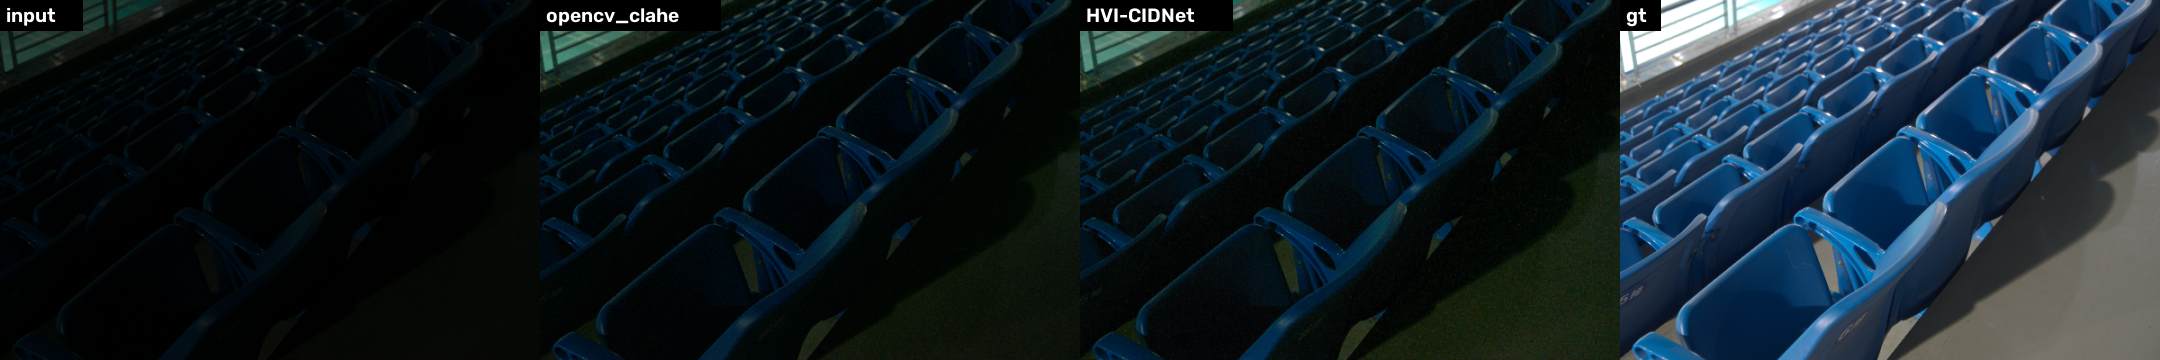

failure_figures\case1_color_shift_00780.png


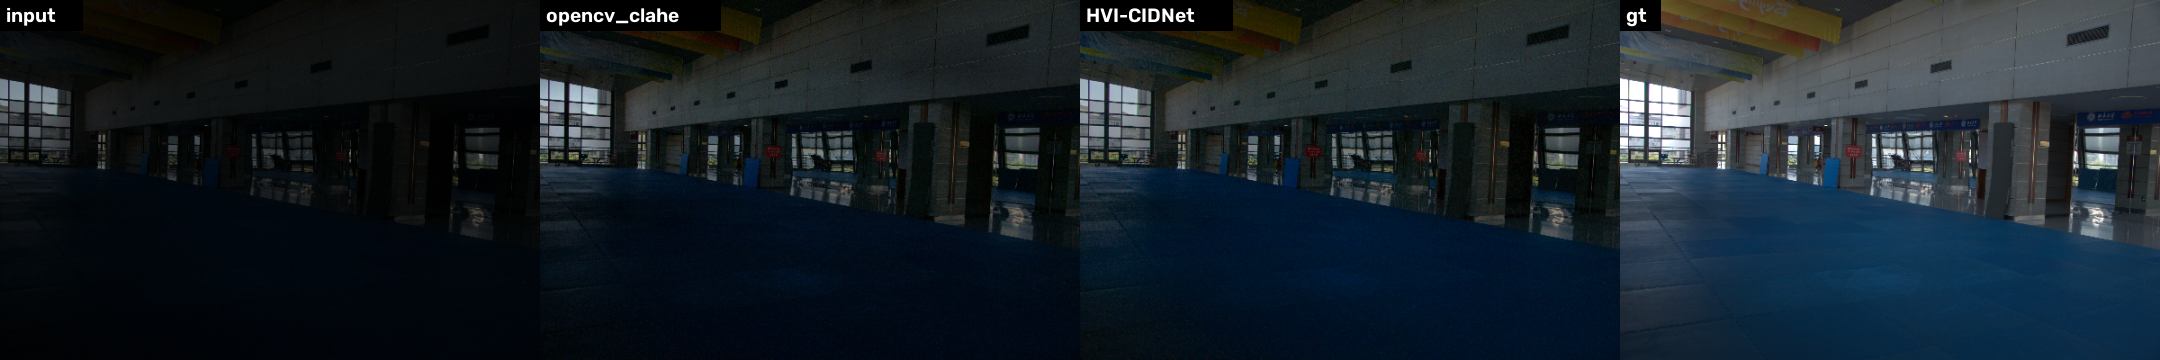

failure_figures\case2_k_alpha_00764.png


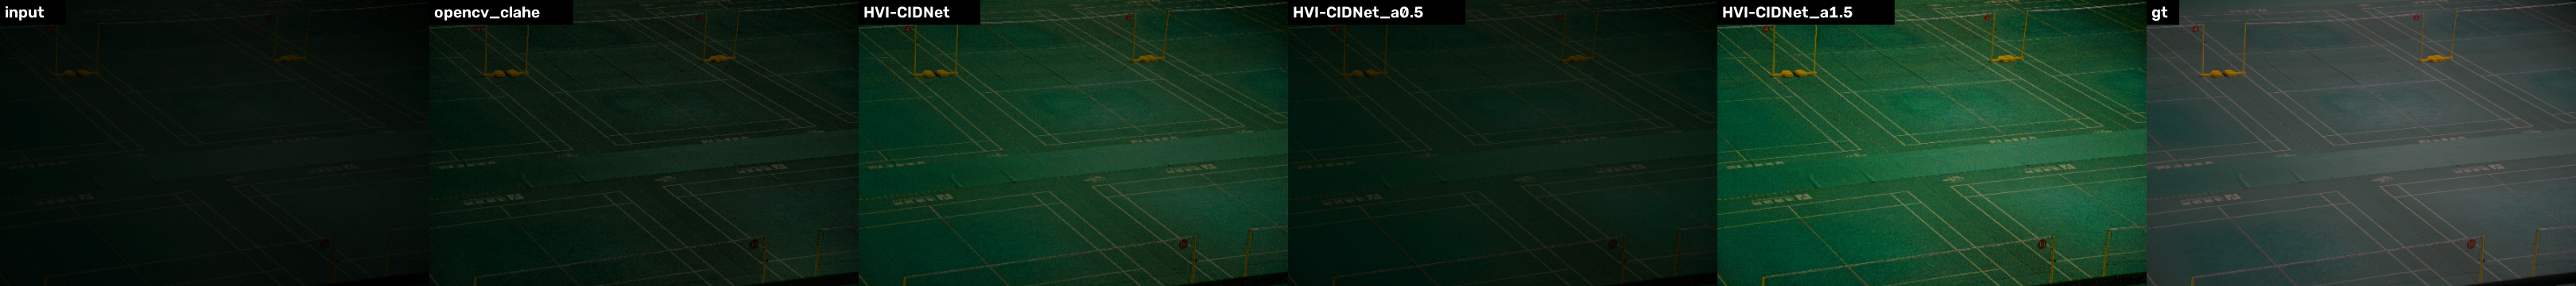

failure_figures\case3_total_dark_dark_03.png


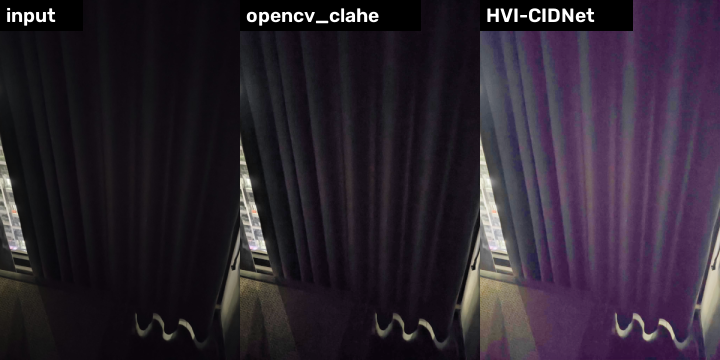

failure_figures\case3_total_dark_dark_04.png


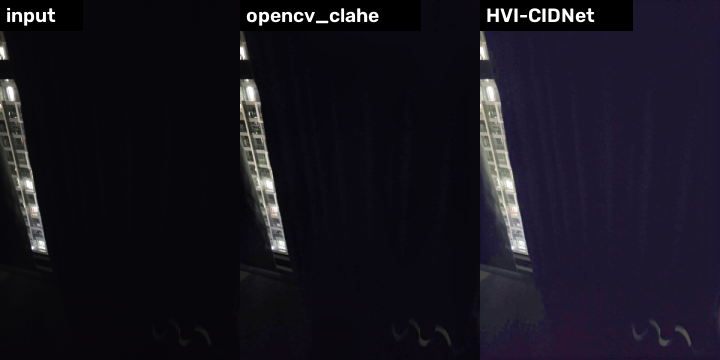

failure_figures\case4_backlit_53.png


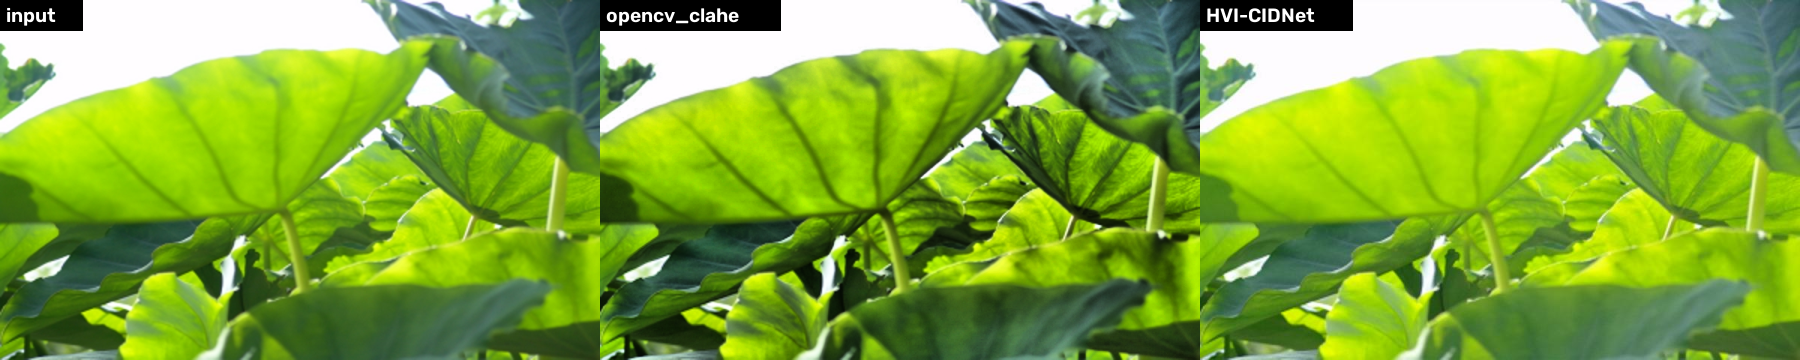

failure_figures\case4_backlit_66.png


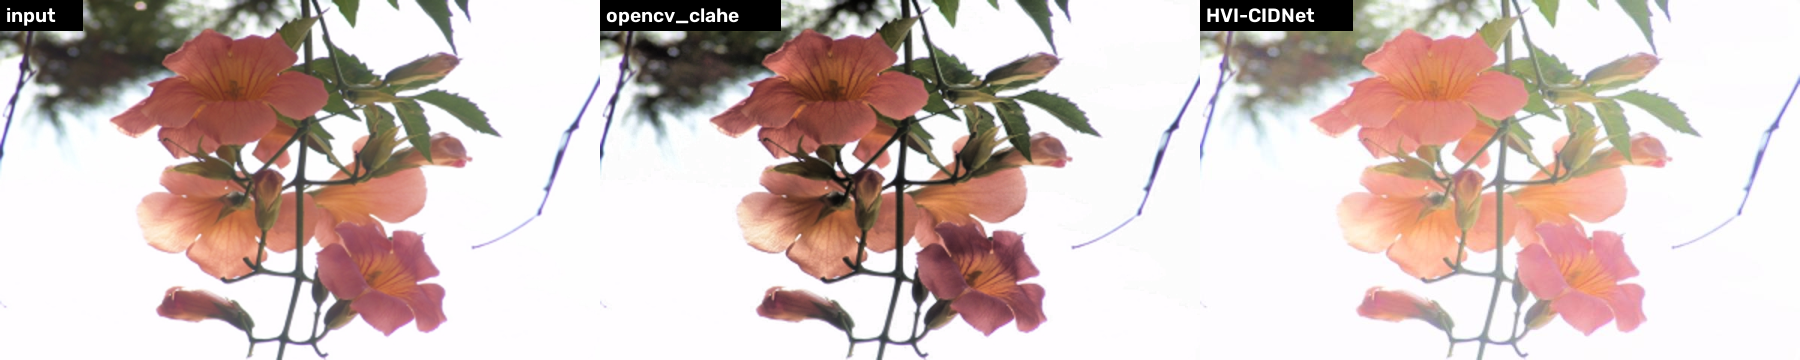

                 case    image           method  sat_pct  dark_pixels_pct  dark_detail  noise_dark  rg_ratio  bg_ratio  rg_ratio_gt  bg_ratio_gt
0   case1_color_shift    00767            input   0.0000          96.3538      26.8172      3.8634    0.4377    1.0085       0.6941       1.2837
1   case1_color_shift    00767     opencv_clahe   0.0000          96.3538     175.0568      9.7466    0.4062    1.0371       0.6941       1.2837
2   case1_color_shift    00767       HVI-CIDNet   0.0000          96.3538     221.7864     12.6578    0.4472    1.0072       0.6941       1.2837
3   case1_color_shift    00780            input   0.0000          93.0750      69.2231      5.1805    0.7095    1.1983       0.7574       1.1942
4   case1_color_shift    00780     opencv_clahe   0.0000          93.0750     333.5664     12.6817    0.7177    1.1900       0.7574       1.1942
5   case1_color_shift    00780       HVI-CIDNet   0.0000          93.0750     313.6771     13.0812    0.6289    1.2429       0.757

In [16]:
# ===== LÀM NỐT BƯỚC 10: tự chọn ảnh, chạy 4 ca, đóng gói kết quả =====
import os, sys, glob, shutil, subprocess
import cv2, numpy as np, pandas as pd

assert "chay_custome" in globals(), "Hãy chạy ô Bước 7 có chữ 'def chay_custome' trước, rồi chạy lại ô này."
EXT = (".png", ".jpg", ".jpeg", ".bmp")
CA = ["case1_color_shift", "case2_k_alpha", "case3_total_dark", "case4_backlit"]

def ds(d):
    return sorted(f for f in os.listdir(d) if f.lower().endswith(EXT)) if os.path.isdir(d) else []
def doc(p):
    return cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
def tim(d, stem):
    for f in ds(d):
        if os.path.splitext(f)[0] == stem:
            return os.path.join(d, f)
def lenh(*a):
    env = dict(os.environ, PYTHONUTF8="1", PYTHONIOENCODING="utf-8")
    r = subprocess.run([sys.executable, *a], capture_output=True, text=True, encoding="utf-8", errors="replace", env=env)
    print((r.stdout or "")[-1500:] + (r.stderr or "")[-1500:])
def chon_anh(ca, bo, f):
    d = f"test_cases/failure_cases/{ca}/input"; os.makedirs(d, exist_ok=True)
    shutil.copy(f"test_cases/{bo}/input/{f}", d)
    g = tim(f"test_cases/{bo}/gt", os.path.splitext(f)[0])
    if g:
        os.makedirs(f"test_cases/failure_cases/{ca}/gt", exist_ok=True)
        shutil.copy(g, f"test_cases/failure_cases/{ca}/gt")
def chay_ca(ca, them=()):
    chay_custome(f"test_cases/failure_cases/{ca}/input", f"results/failure_cases/{ca}/HVI-CIDNet")
    lenh("eval.py", "baselines", "--datasets", f"failure_cases/{ca}")
    pp = ["opencv_clahe", "HVI-CIDNet", *them]
    lenh("failure_cases.py", "panel", "--case", ca, "--methods", *pp)
    lenh("failure_cases.py", "metrics", "--case", ca, "--methods", *pp)

# ---- 0. dọn kết quả cũ của 4 ca để khỏi trùng dòng ----
for ca in CA:
    shutil.rmtree(f"test_cases/failure_cases/{ca}", ignore_errors=True)
    shutil.rmtree(f"results/failure_cases/{ca}", ignore_errors=True)
if os.path.exists("failure_case_metrics.csv"):
    os.remove("failure_case_metrics.csv")

# ---- 1. tự chọn ảnh bằng số liệu ----
lol = []                                   # bộ có ảnh chuẩn: đo lệch màu và lệch độ sáng của HVI-CIDNet
for bo in ["LOLv1", "LOLv2_Real"]:
    for f in ds(f"test_cases/{bo}/input"):
        s = os.path.splitext(f)[0]
        o, g = tim(f"results/{bo}/HVI-CIDNet", s), tim(f"test_cases/{bo}/gt", s)
        if not (o and g):
            continue
        O, G = doc(o).astype(float), doc(g).astype(float)
        if O.shape != G.shape:
            continue
        mau = abs(O[..., 0].mean() / O[..., 1].mean() - G[..., 0].mean() / G[..., 1].mean()) \
            + abs(O[..., 2].mean() / O[..., 1].mean() - G[..., 2].mean() / G[..., 1].mean())
        sang = abs(np.log(O.mean() / max(G.mean(), 1e-6)))
        lol.append((bo, f, mau, sang))
lol = pd.DataFrame(lol, columns=["bo", "file", "lech_mau", "lech_sang"])
c1 = lol.nlargest(2, "lech_mau")
c2 = lol.drop(c1.index).nlargest(1, "lech_sang")

toi = []                                   # ca 3: ảnh chụp tối nhất
for f in ds("test_cases/custom_night/input"):
    g = cv2.cvtColor(cv2.imread(f"test_cases/custom_night/input/{f}"), cv2.COLOR_BGR2GRAY)
    toi.append(("custom_night", f, 100 * float((g <= 40).mean())))
c3 = pd.DataFrame(toi, columns=["bo", "file", "pct_toi"]).nlargest(2, "pct_toi")

chay = []                                  # ca 4: ảnh ra có nhiều điểm cháy sáng nhất
for bo in ["custom_night", "DICM", "LIME"]:
    for f in ds(f"test_cases/{bo}/input"):
        o = tim(f"results/{bo}/HVI-CIDNet", os.path.splitext(f)[0])
        if o:
            chay.append((bo, f, 100 * float((doc(o).min(-1) >= 250).mean())))
c4 = pd.DataFrame(chay, columns=["bo", "file", "pct_chay"]).nlargest(2, "pct_chay")

print("Ca 1 (lệch màu):\n", c1.to_string(index=False))
print("Ca 2 (lệch độ sáng):\n", c2.to_string(index=False))
print("Ca 3 (tối kín):\n", c3.to_string(index=False))
print("Ca 4 (cháy sáng):\n", c4.to_string(index=False))

# ---- 2. chạy từng ca ----
for _, r in c1.iterrows():
    chon_anh("case1_color_shift", r.bo, r.file)
chay_ca("case1_color_shift")

for _, r in c2.iterrows():
    chon_anh("case2_k_alpha", r.bo, r.file)
for a in ["0.5", "1.5"]:                   # thêm hai mức sáng; mức 1.0 là HVI-CIDNet mặc định
    chay_custome("test_cases/failure_cases/case2_k_alpha/input",
                 f"results/failure_cases/case2_k_alpha/HVI-CIDNet_a{a}", alpha=a)
chay_ca("case2_k_alpha", them=["HVI-CIDNet_a0.5", "HVI-CIDNet_a1.5"])

for _, r in c3.iterrows():
    chon_anh("case3_total_dark", r.bo, r.file)
chay_ca("case3_total_dark")

for _, r in c4.iterrows():
    chon_anh("case4_backlit", r.bo, r.file)
chay_ca("case4_backlit")

# ---- 3. xem kết quả và đóng gói ----
from IPython.display import Image, display
for p in sorted(glob.glob("failure_figures/case*_*.png")):
    print(p); display(Image(filename=p))
print(pd.read_csv("failure_case_metrics.csv").to_string())

gui = "ket_qua_gui_claude"
shutil.rmtree(gui, ignore_errors=True); os.makedirs(gui)
for f in ["failure_case_metrics.csv", "quantitative_results.csv", "quantitative_results_custom.csv",
          "per_image_results.csv", "per_image_custom.csv", "histogram_stats.csv"]:
    if os.path.exists(f):
        shutil.copy(f, gui)
shutil.copytree("failure_figures", f"{gui}/failure_figures")
if os.path.exists("test_cases/custom_night/manifest.csv"):
    shutil.copy("test_cases/custom_night/manifest.csv", gui)
shutil.make_archive("ket_qua_gui_claude", "zip", gui)
print("\nXONG. Gửi file ket_qua_gui_claude.zip (nằm cạnh eval.py) lên cho Claude.")

## Bước 11. Lưu và nộp
Các file cần giao: thư mục `test_cases/`, `quantitative_results.csv`, ảnh trong `failure_figures/` và `failure_case_metrics.csv`. Gửi lại hai file CSV cho Claude để điền số vào tài liệu và slide 9–12.